# BSISO_Active_link: results

Active and break monsoon spells over central India, the BSISO, and how far ahead a spell can be predicted.
JJAS (June-September). Forecast tests are out-of-sample (one summer held out at a time, with labels rebuilt
without that summer). p-values come from re-dating whole seasons, never from textbook formulas.

**Contents**
0. Data
1. Spell labels
2. Spells in BSISO phase space
3. How the rain moves with the phase
4. Predicting a spell 7 days ahead
5. Further ahead: 1-20 days
6. Weekly rain anomaly
7. Storms today and spells later
8. Key results

## 0. Data

In [1]:
import os, glob, base64, time, warnings, colorsys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression, Ridge, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from IPython.display import display

warnings.filterwarnings("ignore")
ROOTS = [r for r in os.environ.get("BSISO_DATA", "/kaggle/input").split(os.pathsep) if r]
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)


def find(name, required=True):
    for r in ROOTS:
        hits = sorted(glob.glob(os.path.join(r, "**", name), recursive=True))
        if hits:
            return hits[0]
    if required:
        raise FileNotFoundError(f"{name} not found in the attached datasets")
    return None


SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, RED, NEUT, NULLC, GREEN, BROWN = "#2a78d6", "#eb6834", "#e34948", "#f0efec", "#d9d8d3", "#1baf7a", "#8a5a19"
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True})
WETDRY = LinearSegmentedColormap.from_list("wetdry", [BROWN, NEUT, "#1f6fd1"])
PH_COL = [colorsys.hsv_to_rgb((k - 0.5) / 8, 0.62, 0.86) for k in range(1, 9)]

# ---- IMERG daily rain (lat stored 40 -> 5)
ds = xr.open_dataset(find("imerg_india_025_jjas_2000_2024.nc"))
tp = ds["tp"].values.astype("float32")
lat, lon = ds["lat"].values, ds["lon"].values
times = pd.DatetimeIndex(ds["time"].values).normalize()
ds.close()
years = times.year.values

# ---- BSISO index (APCC); the single missing day 2015-06-21 is interpolated
b = pd.read_csv(find("BSISO.INDEX.NORM.LY.data"), sep=r"\s+", skiprows=1, header=None,
                names=["year", "doy", "pc1", "pc2", "b2pc1", "b2pc2", "amp1", "amp2"])
b["date"] = pd.to_datetime(b["year"].astype(str), format="%Y") + pd.to_timedelta(b["doy"] - 1, unit="D")
b.loc[b[["pc1", "pc2"]].le(-999).any(axis=1), ["pc1", "pc2"]] = np.nan
b[["pc1", "pc2"]] = b[["pc1", "pc2"]].interpolate(limit=1)
b["theta"] = np.mod(np.arctan2(b["pc1"], -b["pc2"]), 2 * np.pi)
b["phase"] = (np.floor(b["theta"] / (np.pi / 4)) + 1).astype(int)
b["amp"] = np.hypot(b["pc1"], b["pc2"])
bs = b.set_index("date")
pc1, pc2, amp, phs = (bs[c].reindex(times).values for c in ("pc1", "pc2", "amp", "phase"))

# ---- LPS catalogue: number of storms and strongest storm on each day
Lp = pd.read_parquet(find("lps_daily_2000_2022.parquet"))
Lp["date"] = pd.to_datetime(Lp["date"]).dt.normalize()
Lp["strength"] = -Lp["min_streamfn"]
dayL = Lp.groupby("date").agg(n_lps=("track_id", "nunique"), lps_str=("strength", "max"))
n_lps = dayL["n_lps"].reindex(times).fillna(0).values
lps_str = (dayL["lps_str"].reindex(times).fillna(0) / 1e7).values

# ---- real BSISO forecast: out-of-sample lasso (60-day history, 5 year-blocks); rebuilt if not attached
lasso_path = find("lasso_bsiso_forecasts.parquet", required=False)
if lasso_path is None:
    print("lasso forecasts not attached: rebuilding them (about 15 minutes)")
    bb = b.dropna(subset=["pc1", "pc2"]).sort_values("date").reset_index(drop=True)
    X = bb[["pc1", "pc2"]].values
    base = np.arange(59, len(X))
    HIST = np.stack([np.concatenate([X[t - 59:t + 1, 0], X[t - 59:t + 1, 1]]) for t in base])
    YRB = bb["date"].dt.year.values[base]
    uyr = np.unique(YRB)
    BLK = np.array([{y: i * 5 // len(uyr) for i, y in enumerate(uyr)}[y] for y in YRB])
    out = []
    for tau in range(1, 21):
        ok = base + tau < len(X)
        pr = np.full((len(base), 2), np.nan)
        for k in range(2):
            tgt = np.full(len(base), np.nan)
            tgt[ok] = X[base[ok] + tau, k]
            for blo in range(5):
                te, tr = (BLK == blo) & ok, (BLK != blo) & ok
                m = LassoCV(cv=3, alphas=np.logspace(-4, 0, 5), max_iter=3000, n_jobs=-1, random_state=0)
                pr[te, k] = m.fit(HIST[tr], tgt[tr]).predict(HIST[te])
        out.append(pd.DataFrame(dict(lead=tau, issue=bb["date"].values[base],
                                     target=bb["date"].values[base] + pd.to_timedelta(tau, "D"),
                                     f1=pr[:, 0], f2=pr[:, 1])))
    LF = pd.concat(out, ignore_index=True).dropna(subset=["f1", "f2"])
    LF.to_parquet(os.path.join(OUT, "lasso_bsiso_forecasts.parquet"), index=False)
else:
    LF = pd.read_parquet(lasso_path)
LF["issue"] = pd.to_datetime(LF["issue"]).dt.normalize()
LFD = {L: g.set_index("issue")[["f1", "f2"]] for L, g in LF.groupby("lead")}

display(pd.DataFrame({
    "dataset": ["IMERG daily rain", "BSISO index", "LPS tracks", "lasso BSISO forecasts"],
    "coverage": [f"JJAS {years.min()}-{years.max()}, {len(times):,} days, 0.25 deg",
                 f"{bs.index.min().date()} to {bs.index.max().date()}",
                 f"JJAS 2000-2022, {Lp['track_id'].nunique()} storms, {len(Lp):,} storm-days",
                 f"leads 1-20 days, out-of-sample"]}).set_index("dataset"))

,coverage
dataset,
IMERG daily rain,"JJAS 2000-2024, 3,050 days, 0.25 deg"
BSISO index,1981-01-01 to 2026-07-04
LPS tracks,"JJAS 2000-2022, 345 storms, 2,232 storm-days"
lasso BSISO forecasts,"leads 1-20 days, out-of-sample"


## 1. Spell labels

In [2]:
# India land mask on the IMERG grid (lat 40 -> 5, lon 60 -> 100), packed bits
MASK_B64 = "AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAADAAAAAAAAAAAAAAAAAAAAAAAAAAPAAAAAAAAAAAAAAAAAAAAAAAAAB/AAAAAAAAAAAAAAAAAAAAAAAD//+AAAAAAAAAAAAAAAAAAAAAAAH//+AAAAAAAAAAAAAAAAAAAAAAAP//8AAAAAAAAAAAAAAAAAAAAAAAf//4AAAAAAAAAAAAAAAAAAAAAAAf//wAAAAAAAAAAAAAAAAAAAAAAA///wAAAAAAAAAAAAAAAAAAAAAAA///gAAAAAAAAAAAAAAAAAAAAAAB///AAAAAAAAAAAAAAAAAAAAAAAA//wAAAAAAAAAAAAAAAAAAAAAAAA//wAAAAAAAAAAAAAAAAAAAAAAAD//gAAAAAAAAAAAAAAAAAAAAAAAf//AAAAAAAAAAAAAAAAAAAAAAAA///AAAAAAAAAAAAAAAAAAAAAAAB///AAAAAAAAAAAAAAAAAAAAAAAD///gAAAAAAAAAAAAAAAAAAAAAAP///gAAAAAAAAAAAAAAAAAAAAAA////wAAAAAAAAAAAAAAAAAAAAAD////4AAAAAAAAAAAAAAAAAAAAAP////wAAAAAAAAAAAAAAAAAAAAAf////AAAAAAAAAAAAAAAAAAAAAB////8AAAAAAAAAAAAAAAAAAAAAD////4AAAAAAAAABgAAAAAAAAAAP////gAAAAAAAAH/AAAAAAAAAAA/////AAAAAAAAA//AAAAAAAAAAD/////wAAAAAAAH/8AAAAAAAAAAP/////4AAAAAAAf//gAAAAAAAAA//////8AAAAgAB///AAAAAAAAB///////+AAADgA///8AAAAAAAAH////////AAAHAAf//4AAAAAAAAf/////////AAOAA///wAAAAAAAB//////////AAeAB//wAAAAAAAAB//////////AA/f//+AAAAAAAAAB//////////+B////4AAAAAAAAAD///////////+f///wAAAAAAAAAH///////////8P///gAAAAAAAAAH///////////wH//+AAAAAAAAAAH///////////4P//8AAAAAAAAAAH///////////4P//wAAAAAAAAAAP///////////gAD/gAAAAAAAAAAf//////////8AAH/AAAAAAAAAAAf//////////4AAf8AAAAAAAAAP////////////8AB/4AAAAAAAAA/////////////4AP9gAAAAAAAAD/////////////wAf4AAAAAAAAAD/////////////gB3wAAAAAAAAAB/////////////ABngAAAAAAAAAB/////////////AAPAAAAAAAAAAB////////////+AAcAAAAAAAAAAB////////////8AAYAAAAAAAAAAH////////////4AAwAAAAAAAAAAP////////////4AAAAAAAAAAAAAP////////////gAAAAAAAAAAAAAP//////////+AAAAAAAAAAAAAAAP+/////////4AAAAAAAAAAAAAAAPx/////////4AAAAAAAAAAAAAAAAB/////////wAAAAAAAAAAAAAAAAD/////////AAAAAAAAAAAAAAAAAH////////8AAAAAAAAAAAAAAAAAP////////gAAAAAAAAAAAAAAAAAf///////8AAAAAAAAAAAAAAAAAA////////gAAAAAAAAAAAAAAAAAB///////+AAAAAAAAAAAAAAAAAAD///////4AAAAAAAAAAAAAAAAAAH///////gAAAAAAAAAAAAAAAAAAP//////+AAAAAAAAAAAAAAAAAAAP//////4AAAAAAAAAAAAAAAAAAAf//////gAAAAAAAAAAAAAAAAAAA//////+AAAAAAAAAAAAAAAAAAAB//////wAAAAAAAAAAAAAAAAAAAB//////AAAAAAAAAAAAAAAAAAAAD/////4AAAAAAAAAAAAAAAAAAAAH/////wAAAAAAAAAAAAAAAAAAAAP/////gAAAAAAAAAAAAAAAAAAAAf////8AAAAAAAAAAAAAAAAAAAAAf////AAAAAAAAAAAAAAAAAAAAAA////4AAAAAAAAAAAAAAAAAAAAAA////gAAAAAAAAAAAAAAAAAAAAAA////AAAAAAAAAAAAAAAAAAAAAAB///+AAAAAAAAAAAAAAAAAAAAAAB///8AAAAAAAAAAAAAAAAAAAAAAD///4AAAAAAAAAAAAAAAAAAAAAAD///wAAAAAAAAAAAAAAAAAAAAAAH///gAAAAAAAAAAAAAAAAAAAAAAP///AAAAAAAAAAAAAAAAAAAAAAAf///AAAAAAAAAAAAAAAAAAAAAAAf//+AAAAAAAAAAAAAAAAAAAAAAA///8AAAAAAAAAAAAAAAAAAAAAAB///wAAAAAAAAAAAAAAAAAAAAAAD///gAAAAAAAAAAAAAAAAAAAAAAD//+AAAAAAAAAAAAAAAAAAAAAAAD//8AAAAAAAAAAAAAAAAAAAAAAAH//4AAAAAAAAAAAAAAAAAAAAAAAH//wAAAAAAAAAAAAAAAAAAAAAAAH//gAAAAAAAAAAAAAAAAAAAAAAAP//AAAAAAAAAAAAAAAAAAAAAAAAf/+AAAAAAAAAAAAAAAAAAAAAAAAf/8AAAAAAAAAAAAAAAAAAAAAAAA//gAAAAAAAAAAAAAAAAAAAAAAAB/+AAAAAAAAAAAAAAAAAAAAAAAAB/8AAAAAAAAAAAAAAAAAAAAAAAAD/wAAAAAAAAAAAAAAAAAAAAAAAAH/wAAAAAAAAAAAAAAAAAAAAAAAAH8AAAAAAAAAAAAAAAAAAAAAAAAAPwAAAAAAAAAAAAAAAAAAAAAAAAAPgAAAAAAAAAAAAAAAAAAAAAAAAAGAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA"
mask = np.unpackbits(np.frombuffer(base64.b64decode(MASK_B64), np.uint8))[:141 * 161].reshape(141, 161).astype(bool)
LA, LO = (lat >= 18) & (lat <= 28), (lon >= 73) & (lon <= 88)
box = mask & (LA[:, None] & LO[None, :])
assert mask.shape == tp.shape[1:] and box.sum() == 2234
cmz = tp[:, box].mean(axis=1)                         # central-India land rain, unweighted mean

keys = times.strftime("%m%d").values
ukeys = np.array(sorted(set(keys)))
kidx = np.searchsorted(ukeys, keys)
NYR, ND = len(np.unique(years)), len(ukeys)


def clim_z(x, fit_rows):
    """Standardise against a 15-day-smoothed calendar-day climatology fitted on fit_rows only."""
    df = pd.DataFrame({"x": x[fit_rows], "k": kidx[fit_rows]})
    m = df.groupby("k").x.mean().reindex(range(ND)).rolling(15, center=True, min_periods=1).mean().values
    s = df.groupby("k").x.std().reindex(range(ND)).rolling(15, center=True, min_periods=1).mean().values
    return (x - m[kidx]) / s[kidx]


def spells(z):
    """+1 active (z >= 1 for >= 3 days), -1 break (z <= -1 for >= 3 days), 0 otherwise."""
    lab = np.zeros(len(z), int)
    for cond, v in ((z >= 1.0, 1), (z <= -1.0, -1)):
        i = 0
        while i < len(z):
            if cond[i]:
                j = i
                while j + 1 < len(z) and cond[j + 1] and years[j + 1] == years[i]:
                    j += 1
                if j - i + 1 >= 3:
                    lab[i:j + 1] = v
                i = j + 1
            else:
                i += 1
    return lab


z_full = clim_z(cmz, np.ones(len(cmz), bool))
lab_full = spells(z_full)
T = pd.DataFrame({"days": [len(lab_full), int((lab_full == 1).sum()), int((lab_full == -1).sum()),
                           int((lab_full == 0).sum())]},
                 index=pd.Index(["all JJAS days", "active", "break", "neutral"], name=f"JJAS {years.min()}-{years.max()}"))
T["share"] = (100 * T["days"] / len(lab_full)).map("{:.1f}%".format)
display(T)
stored = find("spell_drivers_daily.csv", required=False)
if stored:
    st = pd.read_csv(stored)
    st["date"] = pd.to_datetime(st["date"].astype(str), format="%Y%m%d")
    sl = st.set_index("date").reindex(times)["phase"].map({"active": 1, "break": -1, "neutral": 0}).values
    print(f"agreement with the project's stored labels: {100 * (lab_full == sl).mean():.1f}% of days")

,days,share
JJAS 2000-2024,,
all JJAS days,3050,100.0%
active,285,9.3%
break,304,10.0%
neutral,2461,80.7%


agreement with the project's stored labels: 100.0% of days


## 2. Spells in BSISO phase space

,days,active spell,"active, chance",break spell,"break, chance"
BSISO phase,,,,,
inactive,1008,9.3%,7-11%,11.4%,8-12%
1,216,3.7%,6-15%,12.5%,4-15%
2,267,4.1%,6-15%,6.7%,5-15%
3,273,4.8%,5-13%,9.5%,5-14%
4,227,8.8%,6-14%,4.4%,6-16%
5,350,19.4%,6-14%,3.7%,7-16%
6,232,9.1%,5-13%,10.3%,6-17%
7,240,7.1%,5-14%,14.6%,5-15%
8,237,13.9%,4-13%,15.2%,5-15%


pattern across phases 1-8:  active p = 0.002   break p = 0.091


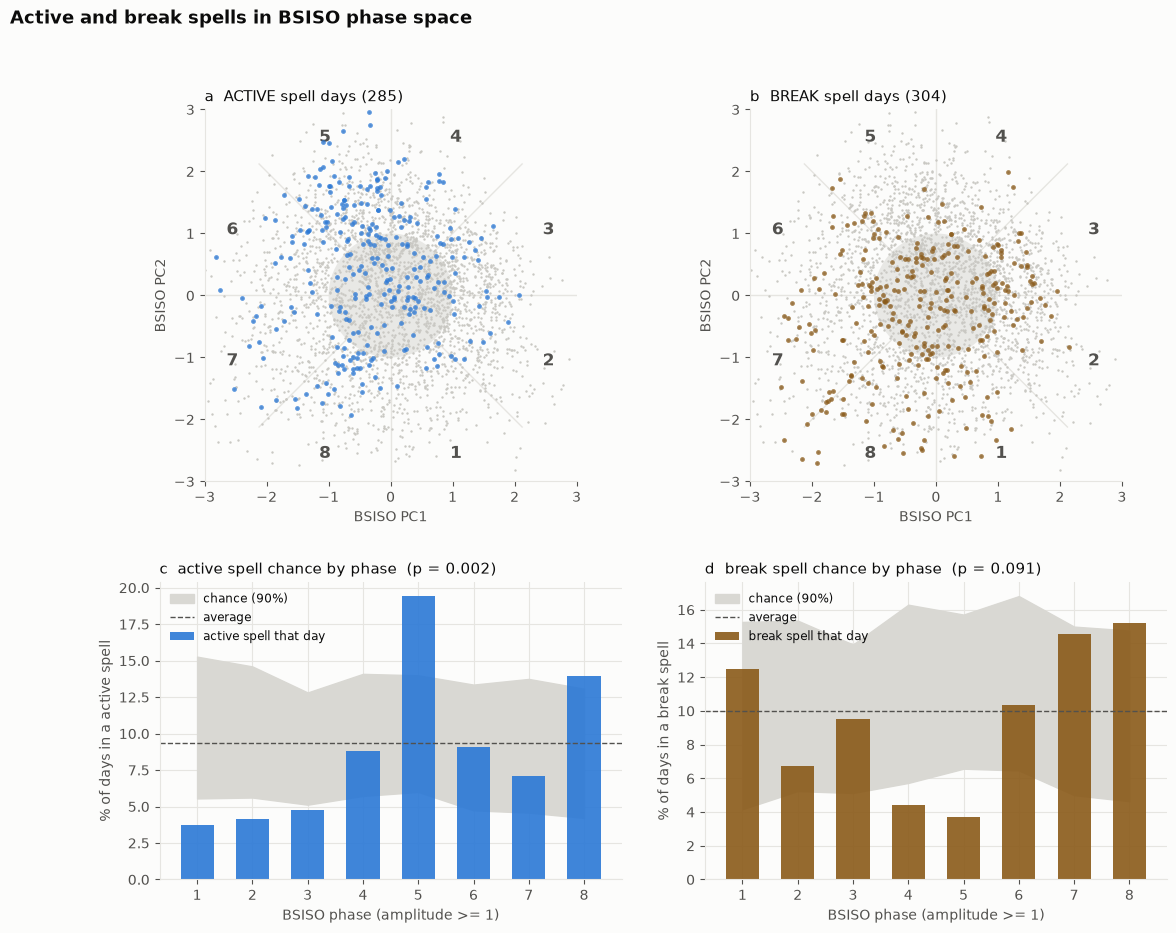

In [3]:
act = amp >= 1
ph_eff = np.where(act, phs, 0)                       # 0 = BSISO inactive (amplitude < 1)


def phase_rates(ph):
    return (np.array([(lab_full[ph == k] == 1).mean() for k in range(9)]),
            np.array([(lab_full[ph == k] == -1).mean() for k in range(9)]))


obs_a, obs_b = phase_rates(ph_eff)
rng = np.random.default_rng(1)
blk = ph_eff.reshape(NYR, ND)
nul = [phase_rates(blk[rng.permutation(NYR)].ravel()) for _ in range(1000)]
null_a, null_b = np.array([n[0] for n in nul]), np.array([n[1] for n in nul])
spread = lambda r, base: float(np.nansum((r[1:] - base) ** 2))
ba, bb_ = (lab_full == 1).mean(), (lab_full == -1).mean()
p_phase_a = (1 + sum(spread(x, ba) >= spread(obs_a, ba) for x in null_a)) / 1001
p_phase_b = (1 + sum(spread(x, bb_) >= spread(obs_b, bb_) for x in null_b)) / 1001
rtxt = lambda n, k: f"{100 * np.percentile(n[:, k], 5):.0f}-{100 * np.percentile(n[:, k], 95):.0f}%"
T = pd.DataFrame({
    "days": [int((ph_eff == k).sum()) for k in range(9)],
    "active spell": [f"{100 * obs_a[k]:.1f}%" for k in range(9)],
    "active, chance": [rtxt(null_a, k) for k in range(9)],
    "break spell": [f"{100 * obs_b[k]:.1f}%" for k in range(9)],
    "break, chance": [rtxt(null_b, k) for k in range(9)]},
    index=pd.Index(["inactive"] + [str(k) for k in range(1, 9)], name="BSISO phase"))
display(T)
print(f"pattern across phases 1-8:  active p = {p_phase_a:.3f}   break p = {p_phase_b:.3f}")

R = 3.0
to_xy = lambda th, r: (r * np.sin(np.deg2rad(th)), -r * np.cos(np.deg2rad(th)))


def frame(a, title):
    a.add_patch(plt.Circle((0, 0), 1, color=NULLC, alpha=0.55, lw=0, zorder=0))
    for k in range(8):
        a.plot(*zip(to_xy(k * 45, 1), to_xy(k * 45, R)), color=GRID, lw=1, zorder=1)
    for k in range(1, 9):
        a.text(*to_xy((k - 0.5) * 45, R * 0.92), str(k), ha="center", va="center", fontsize=12, color=INK2,
               fontweight="bold")
    a.set(xlim=(-R, R), ylim=(-R, R), aspect="equal", xlabel="BSISO PC1", ylabel="BSISO PC2")
    a.grid(False)
    a.set_title(title, loc="left", fontsize=10.5)


fig = plt.figure(figsize=(13, 10))
gs_ = fig.add_gridspec(2, 2, height_ratios=[1.25, 1], hspace=0.3, wspace=0.18)
for j, (v, col, nm) in enumerate(((1, BLUE, "ACTIVE"), (-1, BROWN, "BREAK"))):
    a = fig.add_subplot(gs_[0, j])
    frame(a, f"{'ab'[j]}  {nm} spell days ({int((lab_full == v).sum())})")
    a.scatter(pc1, pc2, s=3, color="#c9c8c3", lw=0, zorder=1)
    a.scatter(pc1[lab_full == v], pc2[lab_full == v], s=12, color=col, alpha=0.75, lw=0, zorder=3)
x8 = np.arange(1, 9)
for j, (obs, nl, v, col, nm, p) in enumerate(((obs_a, null_a, 1, BLUE, "active", p_phase_a),
                                              (obs_b, null_b, -1, BROWN, "break", p_phase_b))):
    a = fig.add_subplot(gs_[1, j])
    a.fill_between(x8, 100 * np.percentile(nl[:, 1:], 5, axis=0), 100 * np.percentile(nl[:, 1:], 95, axis=0),
                   color=NULLC, label="chance (90%)")
    a.bar(x8, 100 * obs[1:], color=col, width=0.6, alpha=0.9, label=f"{nm} spell that day")
    a.axhline(100 * (lab_full == v).mean(), color=INK2, ls="--", lw=1, label="average")
    a.set(xticks=x8, xlabel="BSISO phase (amplitude >= 1)", ylabel=f"% of days in a {nm} spell")
    a.set_title(f"{'cd'[j]}  {nm} spell chance by phase  (p = {p:.3f})", loc="left", fontsize=10.5)
    a.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle("Active and break spells in BSISO phase space", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.savefig(os.path.join(OUT, "fig1_spells_in_phase_space.png"), dpi=140, bbox_inches="tight")
plt.show()

## 3. How the rain moves with the phase

,days,wettest latitude (70-90E),rain anomaly there
BSISO phase,,,
1,216,5.0 N,+2.9 mm/day
2,267,5.2 N,+5.1 mm/day
3,273,10.8 N,+4.5 mm/day
4,227,13.5 N,+4.5 mm/day
5,350,19.0 N,+6.8 mm/day
6,232,19.2 N,+4.3 mm/day
7,240,28.8 N,+0.3 mm/day
8,237,23.8 N,+0.9 mm/day


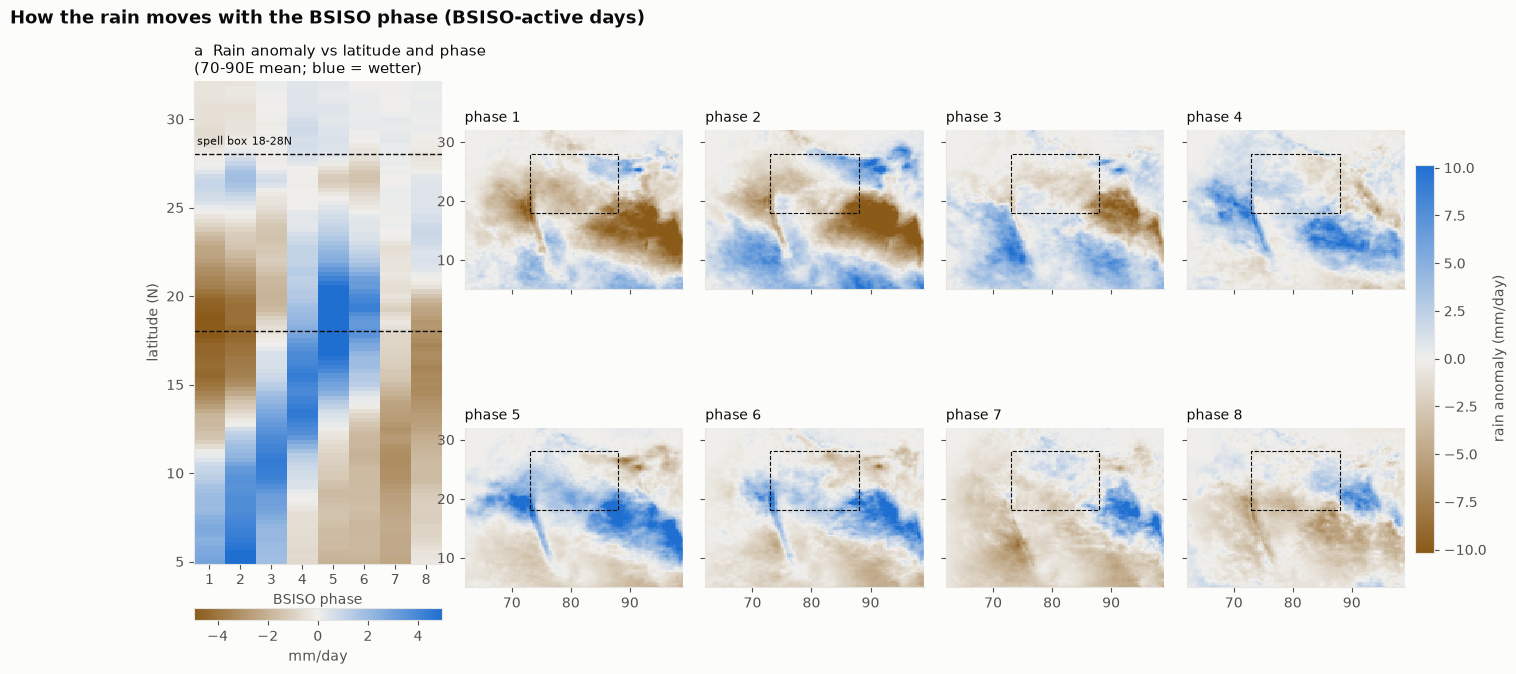

In [4]:
cm = np.stack([tp[kidx == k].mean(axis=0) for k in range(ND)])
cm = pd.DataFrame(cm.reshape(ND, -1)).rolling(15, center=True, min_periods=1).mean().values.reshape(cm.shape)
anom = tp - cm[kidx]
comp = np.stack([anom[act & (phs == k)].mean(axis=0) for k in range(1, 9)])
del anom
hov = comp[:, :, (lon >= 70) & (lon <= 90)].mean(axis=2)
latsel = (lat >= 5) & (lat <= 32)
T = pd.DataFrame({
    "days": [int((act & (phs == k)).sum()) for k in range(1, 9)],
    "wettest latitude (70-90E)": [f"{lat[latsel][np.argmax(hov[k][latsel])]:.1f} N" for k in range(8)],
    "rain anomaly there": [f"{hov[k][latsel].max():+.1f} mm/day" for k in range(8)]},
    index=pd.Index(range(1, 9), name="BSISO phase"))
display(T)

fig = plt.figure(figsize=(16, 7.2))
gs_ = fig.add_gridspec(2, 5, width_ratios=[1.1, 1, 1, 1, 1], hspace=0.16, wspace=0.10)
a = fig.add_subplot(gs_[:, 0])
lim = np.nanpercentile(np.abs(hov[:, latsel]), 98)
im = a.pcolormesh(np.arange(1, 9), lat[latsel], hov[:, latsel].T, cmap=WETDRY, vmin=-lim, vmax=lim, shading="nearest")
a.axhline(18, color=INK, lw=1, ls="--"); a.axhline(28, color=INK, lw=1, ls="--")
a.text(0.6, 28.4, "spell box 18-28N", fontsize=8, color=INK, va="bottom")
a.set(xlabel="BSISO phase", ylabel="latitude (N)", xticks=np.arange(1, 9))
a.grid(False)
a.set_title("a  Rain anomaly vs latitude and phase\n(70-90E mean; blue = wetter)", loc="left", fontsize=10.5)
fig.colorbar(im, ax=a, orientation="horizontal", fraction=0.05, pad=0.08).set_label("mm/day", color=INK2)
lim2 = np.nanpercentile(np.abs(comp), 99)
maps = []
for k in range(8):
    a = fig.add_subplot(gs_[k // 4, 1 + k % 4])
    maps.append(a)
    im2 = a.pcolormesh(lon, lat, comp[k], cmap=WETDRY, vmin=-lim2, vmax=lim2, shading="auto")
    a.add_patch(plt.Rectangle((73, 18), 15, 10, fill=False, ec=INK, lw=0.8, ls="--"))
    a.set(xlim=(62, 99), ylim=(5, 32), aspect="equal", xticks=[70, 80, 90], yticks=[10, 20, 30])
    if k % 4: a.set_yticklabels([])
    if k < 4: a.set_xticklabels([])
    a.grid(False)
    a.set_title(f"phase {k + 1}", loc="left", fontsize=10)
fig.colorbar(im2, ax=maps, fraction=0.02, pad=0.01).set_label("rain anomaly (mm/day)", color=INK2)
fig.suptitle("How the rain moves with the BSISO phase (BSISO-active days)", x=0.01, ha="left", fontsize=13,
             fontweight="bold")
plt.savefig(os.path.join(OUT, "fig2_rain_by_phase.png"), dpi=140, bbox_inches="tight")
plt.show()

## 4. Predicting a spell 7 days ahead
Skill = Brier skill score against climatology (0 = no better than always forecasting the average; higher is better).
"Perfect BSISO" uses the true BSISO on the target day, an upper limit for any BSISO forecast.

In [5]:
FYRS = np.arange(2000, 2023)                         # years covered by the storm catalogue
FOLD = {}
for Y in FYRS:                                       # labels for each held-out year, built without that year
    zf = clim_z(cmz, years != Y)
    FOLD[Y] = (zf, spells(zf))


def bsiso_on(dates):
    return bs[["pc1", "pc2", "amp"]].reindex(pd.DatetimeIndex(dates)).values


def design(L):
    ii = np.array([i for i in range(len(times) - L)
                   if years[i] in FYRS and years[i + L] == years[i] and (times[i + L] - times[i]).days == L])
    jj = ii + L
    nd = len(ii) // len(FYRS)
    shp = lambda v: v.reshape(len(FYRS), nd, -1)
    f = LFD[L].reindex(times[ii]).values if L in LFD else np.full((len(ii), 2), np.nan)
    return dict(
        bt=shp(np.column_stack([pc1[jj], pc2[jj], amp[jj]])),             # true BSISO on the target day
        bt5=shp(bsiso_on(times[jj] - pd.Timedelta(days=5))),              # true BSISO 5 days before the target
        bn=shp(np.column_stack([pc1[ii], pc2[ii], amp[ii]])),             # BSISO today
        bf=shp(np.column_stack([f, np.hypot(f[:, 0], f[:, 1])])),          # real (lasso) forecast for the target
        lp=shp(np.column_stack([n_lps[ii], lps_str[ii]])),                # storms today
        ii=ii.reshape(len(FYRS), nd), jj=jj.reshape(len(FYRS), nd))


def run_model(D, groups, target, perm=None):
    ny, nd = D["ii"].shape
    feats = {g: (D[g][perm[1]] if perm is not None and perm[0] == g else D[g]) for g in groups if g != "z"}
    P, C, Yv, YR = [], [], [], []
    for k, Y in enumerate(FYRS):
        zf, lab = FOLD[Y]
        ylab = (lab[D["jj"]] == target).astype(int)
        cols = [feats[g] for g in groups if g != "z"] + ([zf[D["ii"]][..., None]] if "z" in groups else [])
        tr = np.ones(ny, bool); tr[k] = False
        ytr = ylab[tr].ravel()
        if cols:
            X = np.concatenate(cols, axis=2)
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
            p = m.fit(X[tr].reshape(-1, X.shape[2]), ytr).predict_proba(X[k])[:, 1]
        else:
            p = np.full(nd, ytr.mean())
        P.append(p); C.append(np.full(nd, ytr.mean())); Yv.append(ylab[k]); YR.append(np.full(nd, Y))
    return np.concatenate(P), np.concatenate(C), np.concatenate(Yv), np.concatenate(YR)


def bss(p, c, y):
    return 1 - np.mean((p - y) ** 2) / np.mean((c - y) ** 2)


def scores(p, c, y):
    r = p / c                                        # risk relative to that summer's climatology
    flat = r.std() < 1e-12
    top = r >= np.quantile(r, 0.9)
    return dict(bss=bss(p, c, y), auc=0.5 if flat else roc_auc_score(y, r),
                top10=y.mean() if flat else y[top].mean(), base=y.mean())


def boot(p, c, y, yr, rng, n=1000):
    uy = np.unique(yr)
    idx = {Y: np.where(yr == Y)[0] for Y in uy}
    v = [bss(p[s], c[s], y[s]) for s in (np.concatenate([idx[Y] for Y in rng.choice(uy, len(uy))]) for _ in range(n))]
    return np.percentile(v, [5, 95])


def null_gain(D, groups, g, target, ref, rng, n):
    return np.array([bss(*run_model(D, groups, target, perm=(g, rng.permutation(len(FYRS))))[:3]) - ref
                     for _ in range(n)])

In [6]:
LEAD = 7
D7 = design(LEAD)
M7 = {"climatology": [], "storms today": ["lp"], "rain today": ["z"], "BSISO today": ["bn"],
      "perfect BSISO": ["bt"], "perfect BSISO + storms today": ["bt", "lp"],
      "perfect BSISO + storms + rain today": ["bt", "lp", "z"]}
rng = np.random.default_rng(7)
R7 = {}
for target, tn in ((1, "ACTIVE"), (-1, "BREAK")):
    for nm, g in M7.items():
        p, c, y, yr = run_model(D7, g, target)
        R7[(tn, nm)] = (scores(p, c, y), boot(p, c, y, yr, rng) if g else (0, 0), p, y)
for tn in ("ACTIVE", "BREAK"):
    T = pd.DataFrame([{
        "skill": f"{R7[(tn, nm)][0]['bss']:+.3f}",
        "90% range over summers": "" if nm == "climatology" else f"{R7[(tn, nm)][1][0]:+.3f} to {R7[(tn, nm)][1][1]:+.3f}",
        "AUC": f"{R7[(tn, nm)][0]['auc']:.2f}",
        "spell rate in top-10% forecasts": f"{100 * R7[(tn, nm)][0]['top10']:.0f}%"} for nm in M7],
        index=pd.Index(list(M7), name=f"{tn} spell, {LEAD} days ahead"))
    print(f"{tn}: average rate {100 * R7[(tn, 'climatology')][0]['base']:.1f}%")
    display(T)

N7 = 200
rows = []
for label, groups, g, ref in (("perfect BSISO", ["bt"], "bt", None),
                              ("perfect BSISO, given storms", ["bt", "lp"], "bt", "storms today"),
                              ("storms, given perfect BSISO", ["bt", "lp"], "lp", "perfect BSISO"),
                              ("storms alone", ["lp"], "lp", None)):
    row = {"test": label}
    for target, tn in ((1, "active"), (-1, "break")):
        obs = R7[(tn.upper(), "perfect BSISO + storms today" if len(groups) == 2 else
                  ("perfect BSISO" if g == "bt" else "storms today"))][0]["bss"]
        refv = R7[(tn.upper(), ref)][0]["bss"] if ref else 0.0
        nl = null_gain(D7, groups, g, target, refv, rng, N7)
        row[f"{tn}: gain"] = f"{obs - refv:+.3f}"
        row[f"{tn}: p"] = f"{(1 + np.sum(nl >= obs - refv)) / (N7 + 1):.3f}"
    rows.append(row)
print(f"Does each ingredient add skill beyond chance? ({N7} season re-datings)")
display(pd.DataFrame(rows).set_index("test"))

ACTIVE: average rate 9.4%


,skill,90% range over summers,AUC,spell rate in top-10% forecasts
"ACTIVE spell, 7 days ahead",,,,
climatology,+0.000,,0.50,9%
storms today,-0.004,-0.006 to -0.001,0.43,7%
rain today,+0.015,+0.003 to +0.025,0.66,14%
BSISO today,+0.018,-0.004 to +0.040,0.63,21%
perfect BSISO,+0.017,+0.000 to +0.033,0.64,18%
perfect BSISO + storms today,+0.013,-0.002 to +0.029,0.62,16%
perfect BSISO + storms + rain today,+0.023,-0.005 to +0.047,0.68,20%


BREAK: average rate 10.6%


,skill,90% range over summers,AUC,spell rate in top-10% forecasts
"BREAK spell, 7 days ahead",,,,
climatology,+0.000,,0.50,11%
storms today,-0.002,-0.008 to +0.004,0.52,8%
rain today,+0.000,-0.003 to +0.003,0.53,9%
BSISO today,+0.001,-0.011 to +0.010,0.54,5%
perfect BSISO,+0.009,-0.013 to +0.027,0.61,13%
perfect BSISO + storms today,+0.005,-0.016 to +0.022,0.60,9%
perfect BSISO + storms + rain today,+0.010,-0.017 to +0.031,0.61,15%


Does each ingredient add skill beyond chance? (200 season re-datings)


,active: gain,active: p,break: gain,break: p
test,,,,
perfect BSISO,+0.017,0.005,+0.009,0.020
"perfect BSISO, given storms",+0.017,0.005,+0.007,0.030
"storms, given perfect BSISO",-0.004,0.796,-0.004,0.726
storms alone,-0.004,0.856,-0.002,0.488


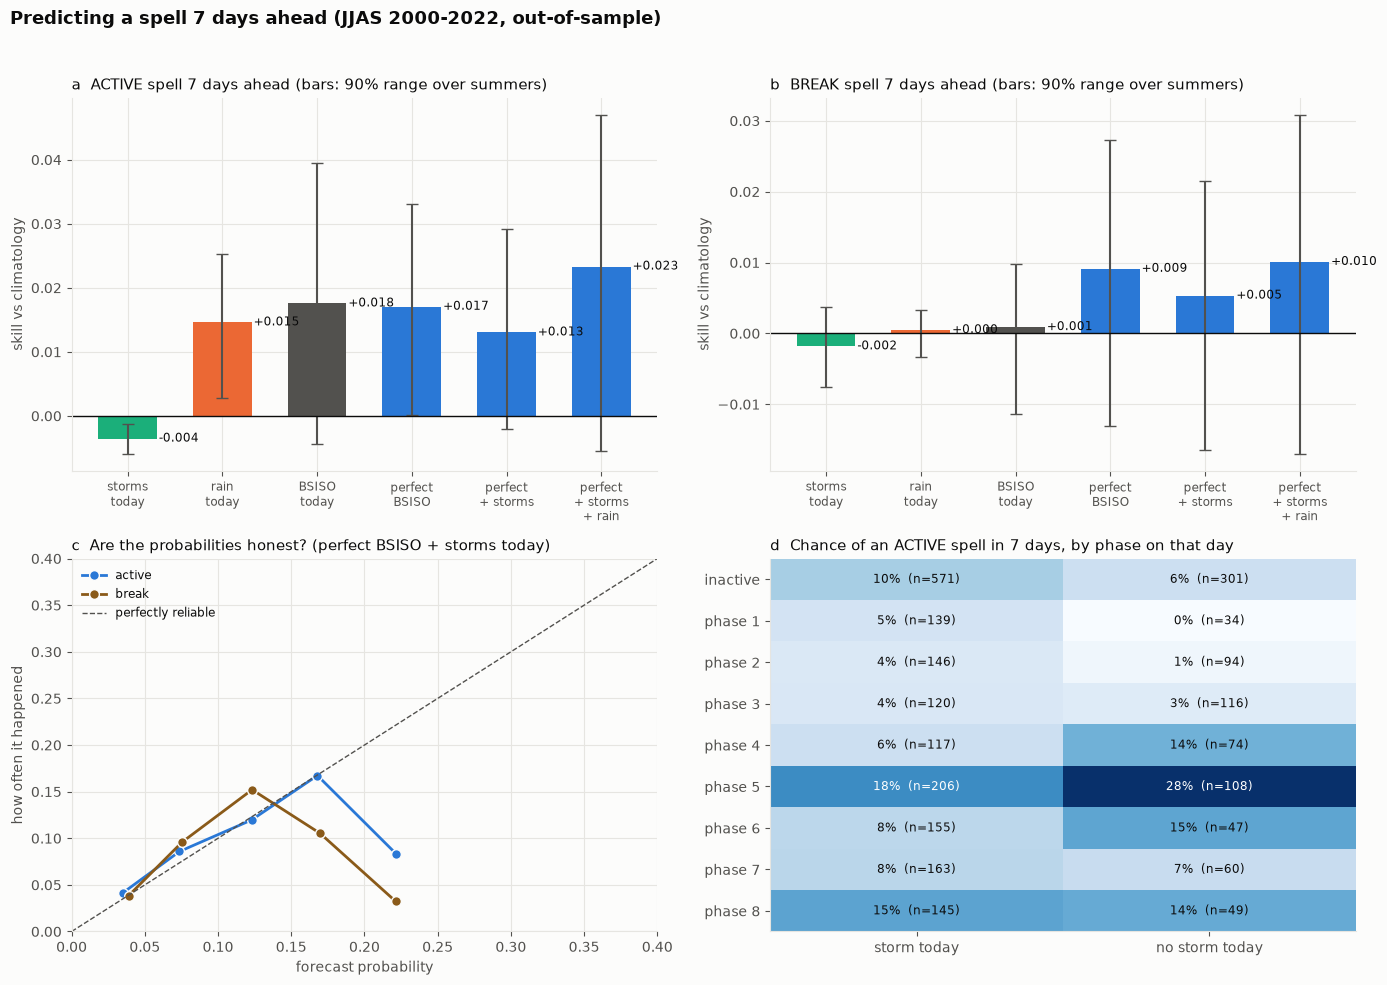

In [7]:
ii7, jj7 = D7["ii"].ravel(), D7["jj"].ravel()
tph = np.where(amp[jj7] >= 1, phs[jj7], 0)
storm_now = n_lps[ii7] > 0
M = np.full((9, 2), np.nan); Nn = np.zeros((9, 2), int)
for k in range(9):
    for c_, s_ in enumerate((True, False)):
        sel = (tph == k) & (storm_now == s_)
        M[k, c_], Nn[k, c_] = 100 * (lab_full[jj7][sel] == 1).mean(), sel.sum()

order = ["storms today", "rain today", "BSISO today", "perfect BSISO", "perfect BSISO + storms today",
         "perfect BSISO + storms + rain today"]
short = ["storms\ntoday", "rain\ntoday", "BSISO\ntoday", "perfect\nBSISO", "perfect\n+ storms", "perfect\n+ storms\n+ rain"]
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for j, tn in enumerate(("ACTIVE", "BREAK")):
    a = ax[0, j]
    v = [R7[(tn, nm)][0]["bss"] for nm in order]
    err = [[v[i] - R7[(tn, nm)][1][0] for i, nm in enumerate(order)], [R7[(tn, nm)][1][1] - v[i] for i, nm in enumerate(order)]]
    cols = [GREEN, ORANGE, INK2, BLUE, BLUE, BLUE]
    a.bar(range(6), v, color=cols, width=0.62, yerr=err, capsize=4, ecolor=INK2)
    a.axhline(0, color=INK, lw=1)
    for x_, vv in enumerate(v):
        a.text(x_ + 0.33, vv, f"{vv:+.3f}", ha="left", va="center", fontsize=8.5)
    a.set_xticks(range(6), short, fontsize=8.5)
    a.set_ylabel("skill vs climatology")
    a.set_title(f"{'ab'[j]}  {tn} spell {LEAD} days ahead (bars: 90% range over summers)", loc="left", fontsize=10.5)
a = ax[1, 0]
for tn, col in (("ACTIVE", BLUE), ("BREAK", BROWN)):
    _, _, p, y = R7[(tn, "perfect BSISO + storms today")]
    bins = np.array([0, 0.05, 0.1, 0.15, 0.2, 0.3, 1.0])
    bi = np.digitize(p, bins) - 1
    ks = [k for k in range(len(bins) - 1) if (bi == k).sum() >= 20]
    a.plot([p[bi == k].mean() for k in ks], [y[bi == k].mean() for k in ks], "o-", color=col, lw=2, ms=7, mec=SURF,
           label=tn.lower())
a.plot([0, 0.4], [0, 0.4], color=INK2, ls="--", lw=1, label="perfectly reliable")
a.set(xlim=(0, 0.4), ylim=(0, 0.4), xlabel="forecast probability", ylabel="how often it happened")
a.set_title("c  Are the probabilities honest? (perfect BSISO + storms today)", loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=8.5, loc="upper left")
a = ax[1, 1]
a.imshow(M, cmap="Blues", aspect="auto", vmin=0, vmax=np.nanmax(M))
a.grid(False)
for k in range(9):
    for c_ in range(2):
        a.text(c_, k, f"{M[k, c_]:.0f}%  (n={Nn[k, c_]})", ha="center", va="center", fontsize=8.5,
               color="white" if M[k, c_] > 0.6 * np.nanmax(M) else INK)
a.set_xticks([0, 1], ["storm today", "no storm today"])
a.set_yticks(range(9), ["inactive"] + [f"phase {k}" for k in range(1, 9)])
a.set_title(f"d  Chance of an ACTIVE spell in {LEAD} days, by phase on that day", loc="left", fontsize=10.5)
fig.suptitle(f"Predicting a spell {LEAD} days ahead (JJAS 2000-2022, out-of-sample)", x=0.01, ha="left", fontsize=13,
             fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(os.path.join(OUT, "fig3_spell_7_days_ahead.png"), dpi=140, bbox_inches="tight")
plt.show()

## 5. Further ahead: 1-20 days
"Real forecast" = the out-of-sample lasso BSISO forecast. "Perfect, 5 d before target" = the true BSISO five days
before the target day (rain over central India responds a few days after the BSISO).

,1 d,3 d,5 d,7 d,10 d,12 d,15 d,20 d
ACTIVE: skill by days ahead,,,,,,,,
BSISO today,+0.018,+0.025,+0.029,+0.018,-0.002,-0.001,+0.005,-0.001
real forecast (lasso),+0.016,+0.024,+0.035,+0.028,+0.006,+0.004,+0.005,-0.001
"perfect, target day",+0.014,+0.015,+0.016,+0.017,+0.017,+0.017,+0.012,+0.007
"perfect, 5 d before target",+0.028,+0.029,+0.029,+0.031,+0.032,+0.035,+0.036,+0.032
storms today,+0.067,+0.026,+0.004,-0.004,-0.000,-0.004,-0.001,+0.003
rain today,+0.281,+0.024,+0.011,+0.015,+0.000,-0.001,-0.001,-0.002


,1 d,3 d,5 d,7 d,10 d,12 d,15 d,20 d
BREAK: skill by days ahead,,,,,,,,
BSISO today,+0.008,+0.003,+0.002,+0.001,+0.005,+0.012,+0.013,-0.002
real forecast (lasso),+0.009,+0.006,+0.008,+0.010,+0.009,+0.013,+0.018,+0.002
"perfect, target day",+0.008,+0.008,+0.008,+0.009,+0.009,+0.010,+0.009,+0.007
"perfect, 5 d before target",+0.002,+0.001,+0.002,+0.002,+0.002,+0.002,-0.000,-0.002
storms today,+0.044,+0.018,-0.000,-0.002,+0.002,+0.002,-0.003,-0.004
rain today,+0.369,+0.068,+0.011,+0.000,-0.001,-0.001,-0.003,-0.002


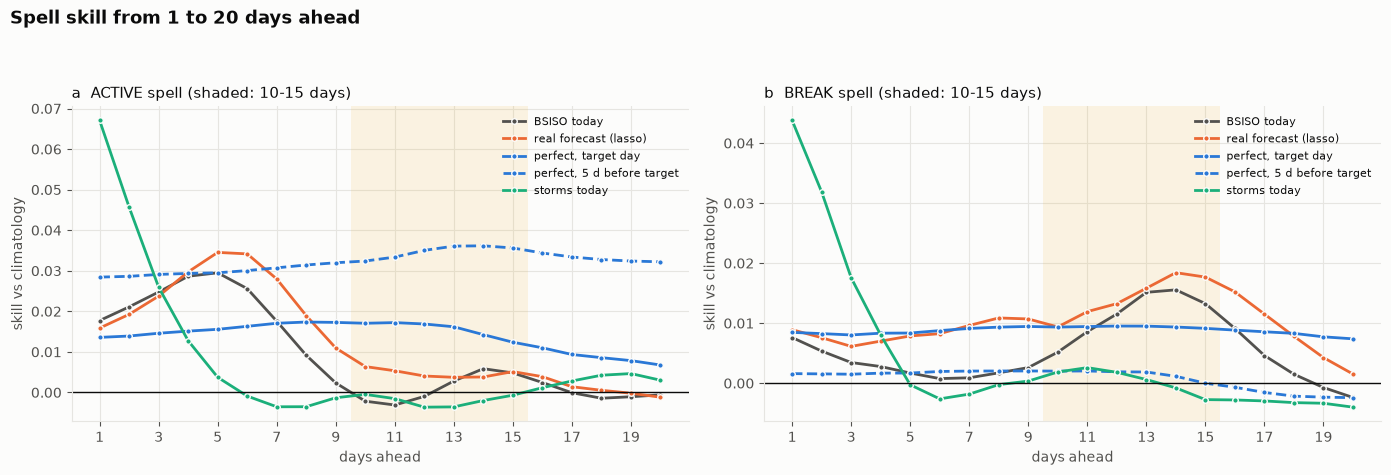

In [8]:
ALL_L = list(range(1, 21))
MF = {"BSISO today": ["bn"], "real forecast (lasso)": ["bf"], "perfect, target day": ["bt"],
      "perfect, 5 d before target": ["bt5"], "storms today": ["lp"], "rain today": ["z"]}
CUR = {}
DL = {L: design(L) for L in ALL_L}
for L in ALL_L:
    for target, tn in ((1, "ACTIVE"), (-1, "BREAK")):
        for nm, g in MF.items():
            CUR[(tn, nm, L)] = scores(*run_model(DL[L], g, target)[:3])
SHOW = [1, 3, 5, 7, 10, 12, 15, 20]
for tn in ("ACTIVE", "BREAK"):
    T = pd.DataFrame({f"{L} d": [f"{CUR[(tn, nm, L)]['bss']:+.3f}" for nm in MF] for L in SHOW},
                     index=pd.Index(list(MF), name=f"{tn}: skill by days ahead"))
    display(T)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for j, tn in enumerate(("ACTIVE", "BREAK")):
    a = ax[j]
    a.axvspan(9.5, 15.5, color="#eda100", alpha=0.10, lw=0)
    for nm, col, ls in (("BSISO today", INK2, "-"), ("real forecast (lasso)", ORANGE, "-"),
                        ("perfect, target day", BLUE, "-"), ("perfect, 5 d before target", BLUE, "--"),
                        ("storms today", GREEN, "-")):
        a.plot(ALL_L, [CUR[(tn, nm, L)]["bss"] for L in ALL_L], ls, color=col, lw=2, marker="o", ms=4, mec=SURF, label=nm)
    a.axhline(0, color=INK, lw=1)
    a.set(xlabel="days ahead", ylabel="skill vs climatology", xticks=list(range(1, 21, 2)))
    a.set_ylim(top=max(0.045, a.get_ylim()[1]) if tn == "ACTIVE" else None)
    a.set_title(f"{'ab'[j]}  {tn} spell (shaded: 10-15 days)", loc="left", fontsize=10.5)
    a.legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Spell skill from 1 to 20 days ahead", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig(os.path.join(OUT, "fig4_skill_by_lead.png"), dpi=140, bbox_inches="tight")
plt.show()

In [9]:
WIN = list(range(10, 16))
NP = 100
rng = np.random.default_rng(15)


def pooled(groups, target, perm=None):
    return float(np.mean([bss(*run_model(DL[L], groups, target, perm=perm)[:3]) for L in WIN]))


rows = []
for label, groups, g, ref in (("perfect, target day", ["bt"], "bt", None),
                              ("perfect, 5 d before target", ["bt5"], "bt5", None),
                              ("real forecast (lasso)", ["bf"], "bf", None),
                              ("BSISO today", ["bn"], "bn", None),
                              ("perfect 5 d before, given today", ["bn", "bt5"], "bt5", ["bn"]),
                              ("real forecast, given today", ["bn", "bf"], "bf", ["bn"])):
    row = {"10-15 days ahead": label}
    for target, tn in ((1, "active"), (-1, "break")):
        refv = pooled(ref, target) if ref else 0.0
        gain = pooled(groups, target) - refv
        nl = np.array([pooled(groups, target, perm=(g, rng.permutation(len(FYRS)))) - refv for _ in range(NP)])
        row[f"{tn}: skill gain"] = f"{gain:+.3f}"
        row[f"{tn}: p"] = f"{(1 + np.sum(nl >= gain)) / (NP + 1):.3f}"
    rows.append(row)
print(f"Average skill over 10-15 days, and whether it beats chance ({NP} season re-datings)")
display(pd.DataFrame(rows).set_index("10-15 days ahead"))
T = pd.DataFrame({f"{tn}: spell rate in top-10%": [f"{100 * np.mean([CUR[(tn, nm, L)]['top10'] for L in WIN]):.0f}%"
                                                   for nm in ("BSISO today", "real forecast (lasso)", "perfect, target day",
                                                              "perfect, 5 d before target")]
                  for tn in ("ACTIVE", "BREAK")},
                 index=pd.Index(["BSISO today", "real forecast (lasso)", "perfect, target day", "perfect, 5 d before target"],
                                name="10-15 days ahead"))
T.loc["(average rate)"] = [f"{100 * np.mean([CUR[(tn, 'BSISO today', L)]['base'] for L in WIN]):.0f}%"
                           for tn in ("ACTIVE", "BREAK")]
display(T)

Average skill over 10-15 days, and whether it beats chance (100 season re-datings)


,active: skill gain,active: p,break: skill gain,break: p
10-15 days ahead,,,,
"perfect, target day",+0.016,0.010,+0.009,0.020
"perfect, 5 d before target",+0.035,0.010,+0.001,0.139
real forecast (lasso),+0.005,0.040,+0.014,0.020
BSISO today,+0.001,0.059,+0.012,0.010
"perfect 5 d before, given today",+0.029,0.010,-0.001,0.188
"real forecast, given today",-0.001,0.168,-0.001,0.208


,ACTIVE: spell rate in top-10%,BREAK: spell rate in top-10%
10-15 days ahead,,
BSISO today,13%,8%
real forecast (lasso),14%,12%
"perfect, target day",16%,13%
"perfect, 5 d before target",24%,5%
(average rate),9%,11%


## 6. Weekly rain anomaly
Target: the 7-day mean rain anomaly around the target day (a smoother target than yes/no spells).
Numbers are out-of-sample correlations.

In [10]:
ZW = {Y: pd.DataFrame(FOLD[Y][0].reshape(NYR, ND).T).rolling(7, center=True, min_periods=7).mean().values.T.ravel()
      for Y in FYRS}
WC = {}


def week_inputs(L):
    if L not in WC:
        D = design(L + 3)
        ii = D["ii"]; jj = ii + L
        ny, nd = ii.shape
        f = LFD[L].reindex(times[ii.ravel()]).values
        WC[L] = (jj, ny, {"bn": D["bn"], "bt": np.stack([pc1[jj], pc2[jj], amp[jj]], -1),
                          "bt5": bsiso_on(times[jj.ravel()] - pd.Timedelta(days=5)).reshape(ny, nd, 3),
                          "bf": np.column_stack([f, np.hypot(f[:, 0], f[:, 1])]).reshape(ny, nd, 3)})
    return WC[L]


def run_week(L, groups, perm=None):
    jj, ny, cols = week_inputs(L)
    cols = dict(cols)
    if perm is not None:
        cols[perm[0]] = cols[perm[0]][perm[1]]
    X = np.concatenate([cols[g] for g in groups], axis=2)
    P, Yv = [], []
    for k, Y in enumerate(FYRS):
        yv = ZW[Y][jj]
        tr = np.ones(ny, bool); tr[k] = False
        m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X[tr].reshape(-1, X.shape[2]), yv[tr].ravel())
        P.append(m.predict(X[k])); Yv.append(yv[k])
    return np.corrcoef(np.concatenate(P), np.concatenate(Yv))[0, 1]


WK = {"BSISO today": ["bn"], "real forecast (lasso)": ["bf"], "perfect, target day": ["bt"],
      "perfect, 5 d before target": ["bt5"]}
SHOWW = [3, 5, 7, 10, 12, 15, 17]
T = pd.DataFrame({f"{L} d": [f"{run_week(L, g):.2f}" for g in WK.values()] for L in SHOWW},
                 index=pd.Index(list(WK), name="correlation by days ahead"))
display(T)
rng = np.random.default_rng(21)
rows = []
for nm, g in WK.items():
    obs = np.mean([run_week(L, g) for L in WIN])
    nl = np.array([np.mean([run_week(L, g, perm=(g[0], rng.permutation(len(FYRS)))) for L in WIN]) for _ in range(NP)])
    rows.append({"10-15 days ahead": nm, "correlation": f"{obs:.2f}",
                 "chance (95%)": f"{np.percentile(nl, 95):.2f}", "p": f"{(1 + np.sum(nl >= obs)) / (NP + 1):.3f}"})
display(pd.DataFrame(rows).set_index("10-15 days ahead"))

,3 d,5 d,7 d,10 d,12 d,15 d,17 d
correlation by days ahead,,,,,,,
BSISO today,0.31,0.28,0.23,0.15,0.16,0.21,0.22
real forecast (lasso),0.31,0.31,0.29,0.23,0.21,0.22,0.21
"perfect, target day",0.30,0.30,0.30,0.30,0.30,0.30,0.29
"perfect, 5 d before target",0.28,0.28,0.28,0.28,0.28,0.29,0.28


,correlation,chance (95%),p
10-15 days ahead,,,
BSISO today,0.17,0.02,0.010
real forecast (lasso),0.22,0.03,0.010
"perfect, target day",0.30,0.01,0.010
"perfect, 5 d before target",0.28,0.01,0.010


## 7. Storms today and spells later

,storm anywhere,storm near central India,chance (90%)
days later: change in active-spell chance with a storm today (points),,,
0,+9.1,+8.9,-3.8 to +2.6
2,+8.5,+6.9,-3.3 to +2.8
4,+6.0,+4.3,-3.0 to +3.0
6,+2.4,+1.1,-3.5 to +2.7
7,+0.1,-0.9,-3.6 to +2.5
8,-1.2,-2.2,-3.7 to +2.3
10,-1.5,-3.9,-3.9 to +2.3
14,-0.8,-2.6,-2.8 to +3.1
18,-3.9,-4.5,-2.8 to +3.0


days with a storm somewhere: 68%   near central India: 58%


,storm today,no storm today,days with a storm
today's state -> active spell 7 days later,,,
active,11.9% (n=219),37.0% (n=27),89%
neutral,9.2% (n=1464),10.1% (n=690),68%
break,5.1% (n=79),0.6% (n=166),32%


Phase 5 on the target day, no storm vs storm today: +9.8 points   chance 95%: +17.7   p = 0.325


,skill without storms,with storms,gain from storms
7 days ahead,,,
active,+0.025,+0.023,-0.002
break,+0.011,+0.010,-0.001


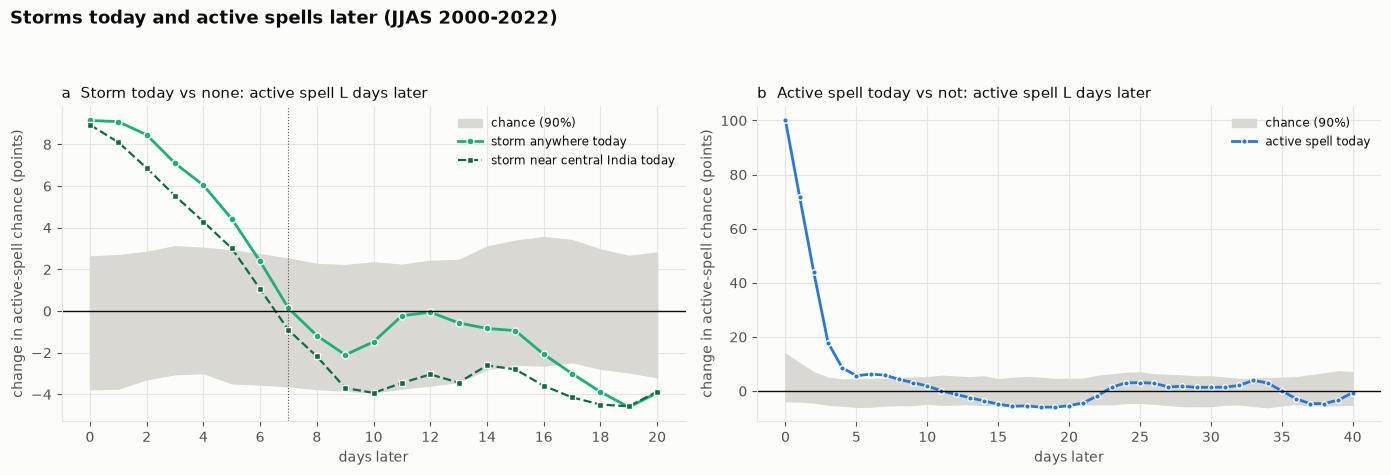

In [11]:
sel_y = np.isin(years, FYRS)
NYf = len(FYRS)
A_ = (lab_full[sel_y] == 1).reshape(NYf, ND)
B_ = (lab_full[sel_y] == -1).reshape(NYf, ND)
S_any = (n_lps[sel_y] > 0).reshape(NYf, ND)
near = Lp[Lp["lat"].between(15, 28) & Lp["lon"].between(70, 90)].groupby("date").size()
S_near = (near.reindex(times[sel_y]).fillna(0).values > 0).reshape(NYf, ND)
rng = np.random.default_rng(3)


def lag_diff(S, Tt, L):
    s, t = S[:, :ND - L].ravel(), Tt[:, L:].ravel()
    return t[s].mean() - t[~s].mean()


def profile(S, Tt, lags):
    obs = np.array([lag_diff(S, Tt, L) for L in lags])
    nl = np.array([[lag_diff(S[p], Tt, L) for L in lags] for p in (rng.permutation(NYf) for _ in range(1000))])
    return obs, np.percentile(nl, 5, axis=0), np.percentile(nl, 95, axis=0)


LAGS = list(range(0, 21))
pa_, pn_ = profile(S_any, A_, LAGS), profile(S_near, A_, LAGS)
LR = list(range(0, 41))
prc = profile(A_, A_, LR)
SL = [0, 2, 4, 6, 7, 8, 10, 14, 18, 20]
display(pd.DataFrame({
    "storm anywhere": [f"{100 * pa_[0][L]:+.1f}" for L in SL],
    "storm near central India": [f"{100 * pn_[0][L]:+.1f}" for L in SL],
    "chance (90%)": [f"{100 * pa_[1][L]:+.1f} to {100 * pa_[2][L]:+.1f}" for L in SL]},
    index=pd.Index(SL, name="days later: change in active-spell chance with a storm today (points)")))
print(f"days with a storm somewhere: {100 * S_any.mean():.0f}%   near central India: {100 * S_near.mean():.0f}%")

L = 7
s, t = S_any[:, :ND - L].ravel(), A_[:, L:].ravel()
state = np.where(A_[:, :ND - L].ravel(), "active", np.where(B_[:, :ND - L].ravel(), "break", "neutral"))
display(pd.DataFrame({
    "storm today": [f"{100 * t[(state == x) & s].mean():.1f}%  (n={((state == x) & s).sum()})" for x in ("active", "neutral", "break")],
    "no storm today": [f"{100 * t[(state == x) & ~s].mean():.1f}%  (n={((state == x) & ~s).sum()})" for x in ("active", "neutral", "break")],
    "days with a storm": [f"{100 * s[state == x].mean():.0f}%" for x in ("active", "neutral", "break")]},
    index=pd.Index(["active", "neutral", "break"], name="today's state -> active spell 7 days later")))

ph_t = np.where(amp[sel_y] >= 1, phs[sel_y], 0).reshape(NYf, ND)[:, L:].ravel()
cell = lambda Sm: t[(ph_t == 5) & ~Sm[:, :ND - L].ravel()].mean() - t[(ph_t == 5) & Sm[:, :ND - L].ravel()].mean()
obs5 = cell(S_any)
nl5 = np.array([cell(S_any[rng.permutation(NYf)]) for _ in range(2000)])
gain_rows = []
for target, tn in ((1, "active"), (-1, "break")):
    b0 = bss(*run_model(D7, ["bt", "z"], target)[:3]); b1 = bss(*run_model(D7, ["bt", "z", "lp"], target)[:3])
    gain_rows.append({"7 days ahead": tn, "skill without storms": f"{b0:+.3f}", "with storms": f"{b1:+.3f}",
                      "gain from storms": f"{b1 - b0:+.3f}"})
print(f"Phase 5 on the target day, no storm vs storm today: {100 * obs5:+.1f} points   "
      f"chance 95%: {100 * np.percentile(nl5, 95):+.1f}   p = {(1 + np.sum(nl5 >= obs5)) / 2001:.3f}")
display(pd.DataFrame(gain_rows).set_index("7 days ahead"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
a = ax[0]
a.fill_between(LAGS, 100 * pa_[1], 100 * pa_[2], color=NULLC, label="chance (90%)")
a.plot(LAGS, 100 * pa_[0], "o-", color=GREEN, lw=2, ms=5, mec=SURF, label="storm anywhere today")
a.plot(LAGS, 100 * pn_[0], "s--", color="#0e6b4a", lw=1.6, ms=4, mec=SURF, label="storm near central India today")
a.axhline(0, color=INK, lw=1); a.axvline(7, color=INK2, lw=0.8, ls=":")
a.set(xlabel="days later", ylabel="change in active-spell chance (points)", xticks=list(range(0, 21, 2)))
a.set_title("a  Storm today vs none: active spell L days later", loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=8.5, loc="upper right")
a = ax[1]
a.fill_between(LR, 100 * prc[1], 100 * prc[2], color=NULLC, label="chance (90%)")
a.plot(LR, 100 * prc[0], "o-", color=BLUE, lw=2, ms=4, mec=SURF, label="active spell today")
a.axhline(0, color=INK, lw=1)
a.set(xlabel="days later", ylabel="change in active-spell chance (points)", xticks=list(range(0, 41, 5)))
a.set_title("b  Active spell today vs not: active spell L days later", loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle("Storms today and active spells later (JJAS 2000-2022)", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig(os.path.join(OUT, "fig5_storms_and_spells_later.png"), dpi=140, bbox_inches="tight")
plt.show()

## 8. Key results

In [12]:
g = lambda tn, nm, L: CUR[(tn, nm, L)]["bss"]
mean_w = lambda tn, nm: np.mean([g(tn, nm, L) for L in WIN])
display(pd.DataFrame({"result": [
    f"Active spells peak in BSISO phase 5 ({100 * obs_a[5]:.0f}% of days vs {100 * ba:.0f}% average); pattern p = {p_phase_a:.3f}",
    f"Break spells lean to phases 7-8; pattern p = {p_phase_b:.3f} (not significant)",
    "The rain band marches north with the phase: ~5N (phases 1-2) to ~19N (phases 5-6)",
    f"7 days ahead, perfect BSISO: skill {R7[('ACTIVE', 'perfect BSISO')][0]['bss']:+.3f} active, "
    f"{R7[('BREAK', 'perfect BSISO')][0]['bss']:+.3f} break; BSISO today already gives {R7[('ACTIVE', 'BSISO today')][0]['bss']:+.3f} active",
    f"Storms today help only 1-4 days ahead (skill {g('ACTIVE', 'storms today', 1):+.3f} at 1 day, {g('ACTIVE', 'storms today', 7):+.3f} at 7)",
    f"10-15 days, active: ceiling (perfect BSISO 5 d before target) {mean_w('ACTIVE', 'perfect, 5 d before target'):+.3f}; "
    f"lasso {mean_w('ACTIVE', 'real forecast (lasso)'):+.3f}; BSISO today {mean_w('ACTIVE', 'BSISO today'):+.3f}",
    f"10-15 days, break: BSISO today {mean_w('BREAK', 'BSISO today'):+.3f} already matches perfect "
    f"{mean_w('BREAK', 'perfect, target day'):+.3f}",
    f"Weekly rain anomaly, 10-15 days: correlation {np.mean([run_week(L, ['bt']) for L in WIN]):.2f} (perfect) vs "
    f"{np.mean([run_week(L, ['bf']) for L in WIN]):.2f} (lasso)",
    f"'No storm today -> more active spells in 7 days' (phase 5): not significant, p = {(1 + np.sum(nl5 >= obs5)) / 2001:.2f}"]},
    index=pd.RangeIndex(1, 10, name="#")).style.set_properties(**{"text-align": "left"}).hide(axis="index"))

result
Active spells peak in BSISO phase 5 (19% of days vs 9% average); pattern p = 0.002
Break spells lean to phases 7-8; pattern p = 0.091 (not significant)
The rain band marches north with the phase: ~5N (phases 1-2) to ~19N (phases 5-6)
"7 days ahead, perfect BSISO: skill +0.017 active, +0.009 break; BSISO today already gives +0.018 active"
"Storms today help only 1-4 days ahead (skill +0.067 at 1 day, -0.004 at 7)"
"10-15 days, active: ceiling (perfect BSISO 5 d before target) +0.035; lasso +0.005; BSISO today +0.001"
"10-15 days, break: BSISO today +0.012 already matches perfect +0.009"
"Weekly rain anomaly, 10-15 days: correlation 0.30 (perfect) vs 0.22 (lasso)"
"'No storm today -> more active spells in 7 days' (phase 5): not significant, p = 0.32"
